# Задание 1. Обучите классификатор Random Forest для решения задачи бинарной классификации: для каждого человека научиться предсказывать, выживет ли он при крушении Титаника.

---

### Устанавливаем зависимости

In [1]:
!pip install -q numpy pandas matplotlib seaborn scikit-learn

### Импортируем датасет

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, RandomizedSearchCV,
                                     GridSearchCV, StratifiedKFold, cross_val_score)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')              # без целевой переменной (для Kaggle)
gender_sub = pd.read_csv('data/gender_submission.csv')

print(train_df.shape, test_df.shape)

(891, 12) (418, 11)


### Производим разведовательный анализ данных

Получим представление о данных в датасете:

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


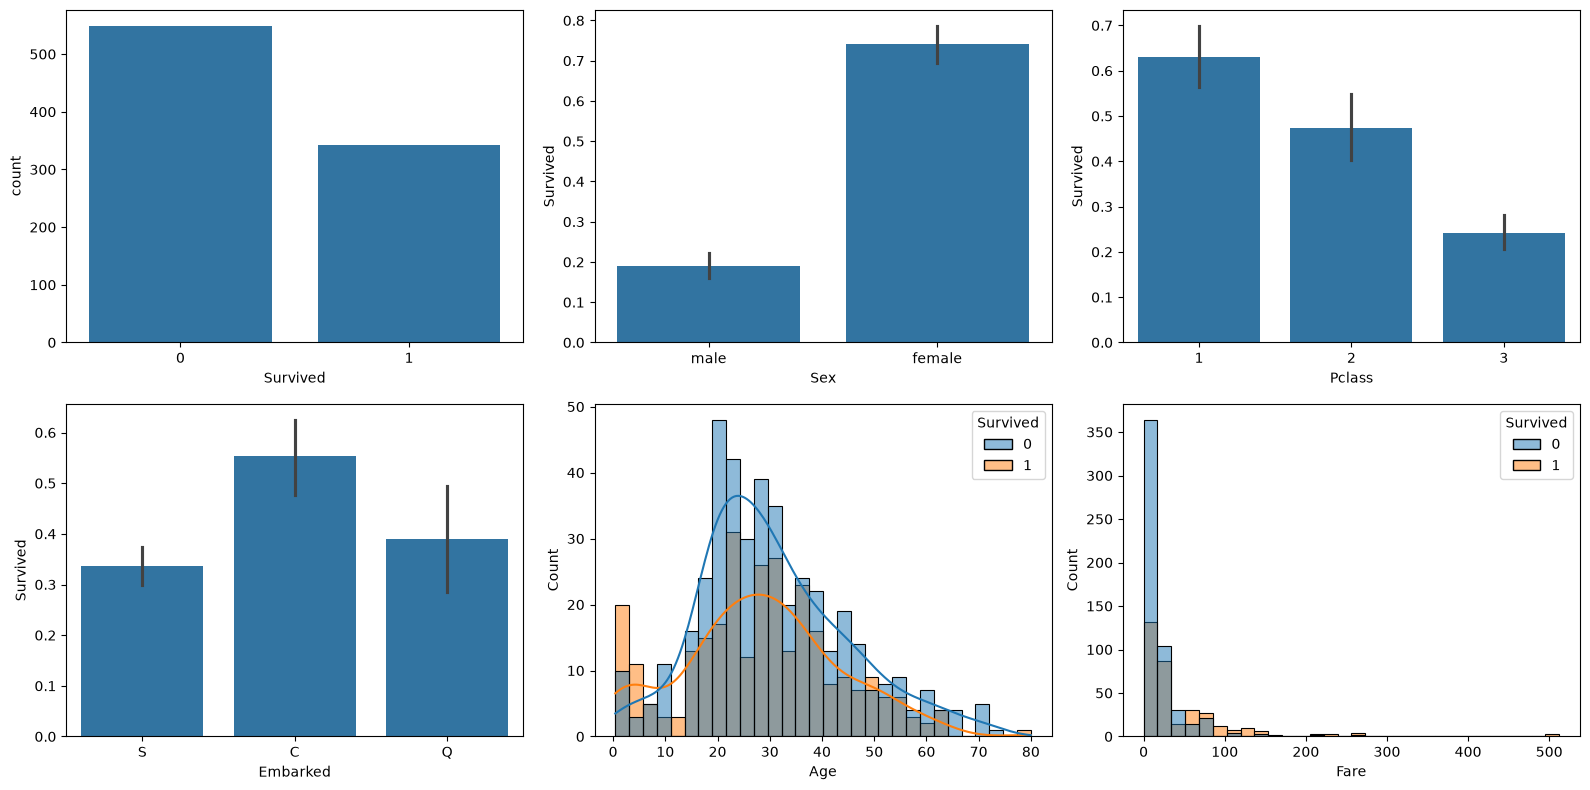

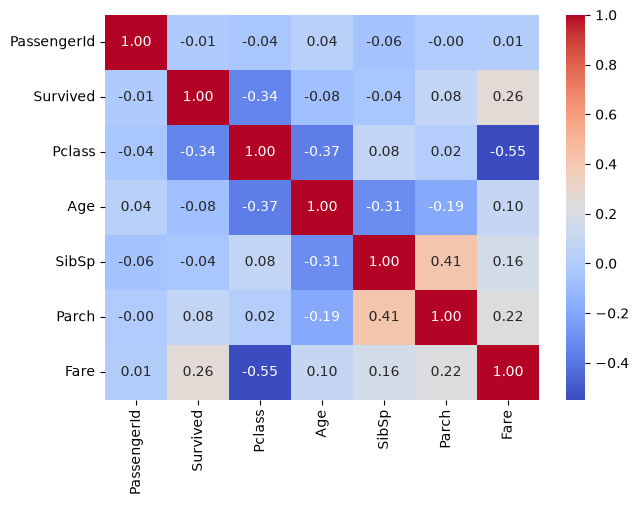

In [3]:
display(train_df.head())
train_df.info()
display(train_df.describe())
print(train_df.isna().sum())

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.countplot(x='Survived', data=train_df, ax=axes[0, 0])
sns.barplot(x='Sex', y='Survived', data=train_df, ax=axes[0, 1])
sns.barplot(x='Pclass', y='Survived', data=train_df, ax=axes[0, 2])
sns.barplot(x='Embarked', y='Survived', data=train_df, ax=axes[1, 0])
sns.histplot(data=train_df, x='Age', hue='Survived', bins=30, kde=True, ax=axes[1, 1])
sns.histplot(data=train_df, x='Fare', hue='Survived', bins=30, ax=axes[1, 2])
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(train_df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

### Сформируем обучающую и тестовую выборки:

In [4]:
X = train_df.drop(columns='Survived')
y = train_df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(712, 11) (179, 11)
0.38342696629213485 0.3854748603351955


### Feature Engineering

Поработаем с признаками, выделим важные, изменим форму их представления (при надобности)

In [5]:
TITLE_MAP = {'Mr': 'Mr', 'Mrs': 'Mrs', 'Miss': 'Miss', 'Master': 'Master',
             'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'}

def get_title(name):
    t = name.split(',')[1].split('.')[0].strip()
    return TITLE_MAP.get(t, 'Rare')

# статистики по train
age_by_title = X_train.assign(Title=X_train['Name'].map(get_title)).groupby('Title')['Age'].median()
age_median = X_train['Age'].median()
fare_by_class = X_train.groupby('Pclass')['Fare'].median()
embarked_mode = X_train['Embarked'].mode()[0]

def preprocess(df):
    d = df.copy()
    d['Title'] = d['Name'].map(get_title)
    d['Age'] = d['Age'].fillna(d['Title'].map(age_by_title)).fillna(age_median)
    d['Fare'] = d['Fare'].fillna(d['Pclass'].map(fare_by_class))
    d['Embarked'] = d['Embarked'].fillna(embarked_mode)
    d['FamilySize'] = d['SibSp'] + d['Parch'] + 1
    d['IsAlone'] = (d['FamilySize'] == 1).astype(int)
    d['HasCabin'] = d['Cabin'].notna().astype(int)
    d['Sex'] = (d['Sex'] == 'female').astype(int)
    d = pd.get_dummies(d, columns=['Embarked', 'Title'], dtype=int)
    return d.drop(columns=['PassengerId', 'Survived', 'Name', 'Ticket', 'Cabin'], errors='ignore')

X_train_p = preprocess(X_train)
X_test_p = preprocess(X_test).reindex(columns=X_train_p.columns, fill_value=0)
kaggle_test_p = preprocess(test_df).reindex(columns=X_train_p.columns, fill_value=0)

print(X_train_p.shape)
display(X_train_p.head())
print(X_train_p.isna().sum().sum())

(712, 17)


,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,HasCabin,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
692,3,0,30.0,0,0,56.4958,1,1,0,0,0,1,0,0,1,0,0
481,2,0,30.0,0,0,0.0000,1,1,0,0,0,1,0,0,1,0,0
527,1,0,30.0,0,0,221.7792,1,1,1,0,0,1,0,0,1,0,0
855,3,1,18.0,0,1,9.3500,2,0,0,0,0,1,0,0,0,1,0
801,2,1,31.0,1,1,26.2500,3,0,0,0,0,1,0,0,0,1,0


0


### Построение базовой модели:

In [6]:
rf_base = RandomForestClassifier(n_estimators=100, random_state=42)
rf_base.fit(X_train_p, y_train)
y_pred_base = rf_base.predict(X_test_p)

### Оценка точности модели:

Напишите функцию, принимающую на вход аргументы y_pred, y_test и выполняющую визуализацию матрицы ошибок и отчета классификации

In [7]:
def evaluate(y_pred, y_test, title='Модель'):
    print(f'=== {title} ===')
    print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}\n')
    print(classification_report(y_test, y_pred, target_names=['Погиб', 'Выжил']))
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Погиб', 'Выжил']).plot(cmap='Blues')
    plt.title(title)
    plt.show()

**Оцените точность модели:**

=== Random Forest (базовая) ===
Accuracy: 0.7933

              precision    recall  f1-score   support

       Погиб       0.83      0.84      0.83       110
       Выжил       0.74      0.72      0.73        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179



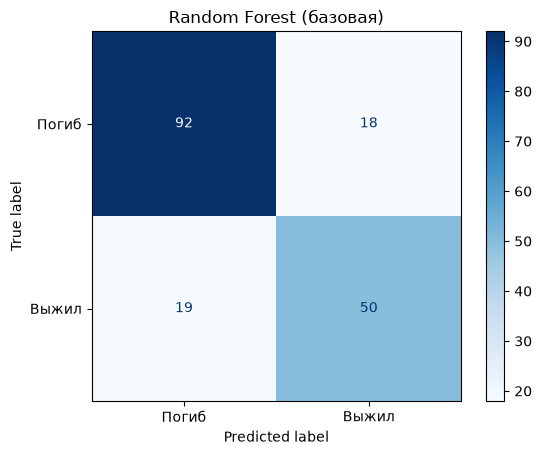

CV accuracy: 0.8118 ± 0.0200


In [8]:
evaluate(y_pred_base, y_test, 'Random Forest (базовая)')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_base = cross_val_score(rf_base, X_train_p, y_train, cv=cv, scoring='accuracy')
print(f'CV accuracy: {cv_base.mean():.4f} ± {cv_base.std():.4f}')

### Настройка гиперпараметров модели:

RandomSearchCV

In [9]:
param_dist = {
    'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [None, 3, 4, 5, 6, 8, 10, 15],
    'min_samples_split': [2, 4, 6, 8, 10],
    'min_samples_leaf': [1, 2, 3, 4, 5],
    'max_features': ['sqrt', 'log2', 0.5, None],
    'bootstrap': [True, False],
    'class_weight': [None, 'balanced'],
}

rand_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=60, cv=cv, scoring='accuracy',
    n_jobs=-1, random_state=42, verbose=1)
rand_search.fit(X_train_p, y_train)

print('Лучшие параметры:', rand_search.best_params_)
print(f'Лучший CV accuracy: {rand_search.best_score_:.4f}')

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Лучшие параметры: {'n_estimators': 300, 'min_samples_split': 8, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 4, 'class_weight': None, 'bootstrap': False}
Лучший CV accuracy: 0.8399


GridSearchCV

In [10]:
bp = rand_search.best_params_

param_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [bp['max_depth']] if bp['max_depth'] is None
                 else sorted({max(2, bp['max_depth'] - 1), bp['max_depth'], bp['max_depth'] + 1}),
    'min_samples_split': sorted({max(2, bp['min_samples_split'] - 2), bp['min_samples_split'], bp['min_samples_split'] + 2}),
    'min_samples_leaf': sorted({max(1, bp['min_samples_leaf'] - 1), bp['min_samples_leaf'], bp['min_samples_leaf'] + 1}),
    'max_features': [bp['max_features']],
    'bootstrap': [bp['bootstrap']],
    'class_weight': [bp['class_weight']],
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid, cv=cv, scoring='accuracy',
    n_jobs=-1, verbose=1)
grid_search.fit(X_train_p, y_train)

print('Лучшие параметры:', grid_search.best_params_)
print(f'Лучший CV accuracy: {grid_search.best_score_:.4f}')

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Лучшие параметры: {'bootstrap': False, 'class_weight': None, 'max_depth': 4, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 300}
Лучший CV accuracy: 0.8413


### Оценка лучшей модели:

=== Random Forest (настроенная) ===
Accuracy: 0.8101

              precision    recall  f1-score   support

       Погиб       0.83      0.87      0.85       110
       Выжил       0.78      0.71      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179



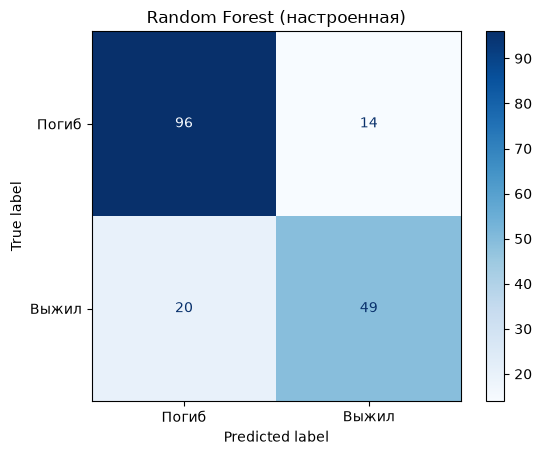

Test accuracy: базовая 0.7933 -> настроенная 0.8101


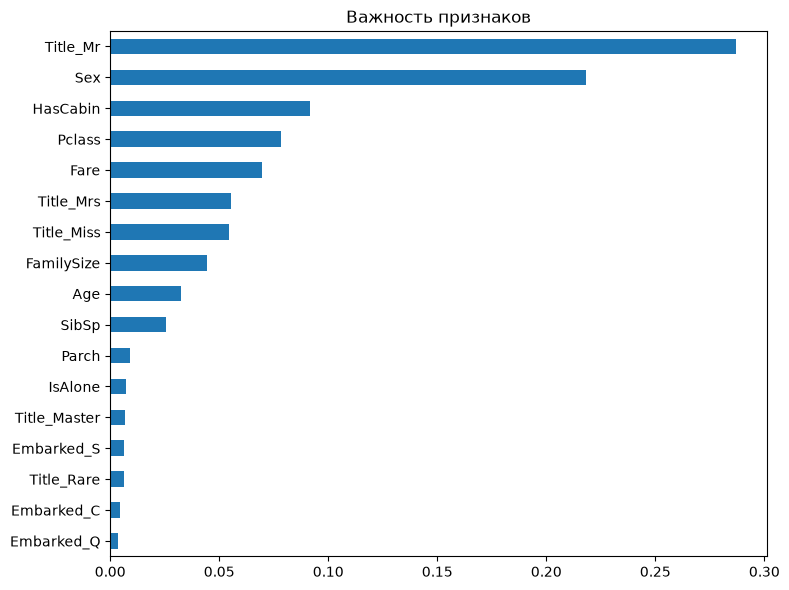

In [11]:
# выбираем лучшую по CV-качеству
best_rf = grid_search.best_estimator_ if grid_search.best_score_ >= rand_search.best_score_ \
          else rand_search.best_estimator_

y_pred_best = best_rf.predict(X_test_p)
evaluate(y_pred_best, y_test, 'Random Forest (настроенная)')

print(f'Test accuracy: базовая {accuracy_score(y_test, y_pred_base):.4f} '
      f'-> настроенная {accuracy_score(y_test, y_pred_best):.4f}')

# важность признаков
imp = pd.Series(best_rf.feature_importances_, index=X_train_p.columns).sort_values()
imp.plot(kind='barh', figsize=(8, 6), title='Важность признаков')
plt.tight_layout()
plt.show()

# Задание 2. Решите задачу из предыдущего пункта используя другие, ранее изученные классификаторы. Сравните их точность предсказания с Random Forest

---

/home/howard/.local/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/howard/.local/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/howard/.local/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/howard/.local/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be remov

,CV accuracy,Test accuracy,Precision,Recall,F1
Модель,,,,,
Logistic Regression,0.8273,0.8436,0.8060,0.7826,0.7941
SVM (RBF),0.8329,0.8268,0.7969,0.7391,0.7669
Gradient Boosting,0.8231,0.8156,0.8000,0.6957,0.7442
Naive Bayes,0.8118,0.8101,0.7397,0.7826,0.7606
Random Forest (настроенный),0.8413,0.8101,0.7778,0.7101,0.7424
kNN,0.8090,0.7877,0.7313,0.7101,0.7206
Decision Tree,0.8146,0.7821,0.8000,0.5797,0.6723


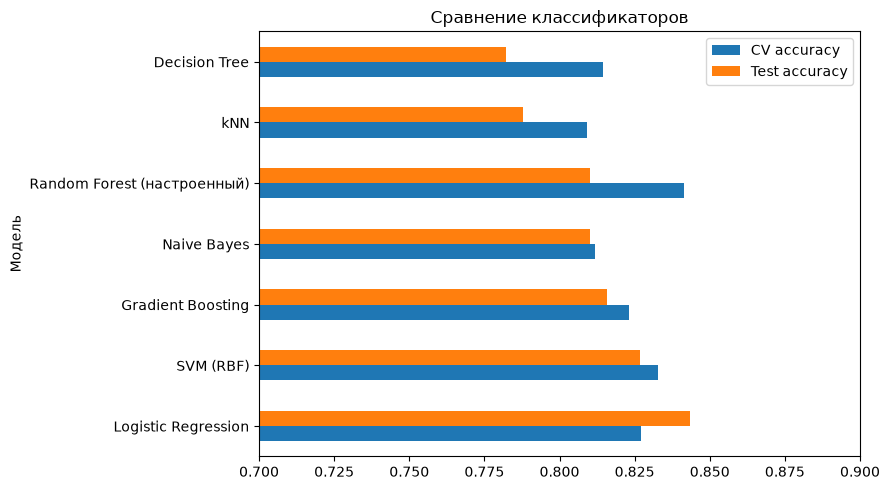

In [12]:
models = {
    'Random Forest (настроенный)': best_rf,
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'kNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    'SVM (RBF)': make_pipeline(StandardScaler(), SVC(probability=True, random_state=42)),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Naive Bayes': GaussianNB(),
}

rows = []
for name, model in models.items():
    if name != 'Random Forest (настроенный)':
        model.fit(X_train_p, y_train)
    pred = model.predict(X_test_p)
    cv_acc = cross_val_score(model, X_train_p, y_train, cv=cv, scoring='accuracy').mean()
    rows.append({
        'Модель': name,
        'CV accuracy': cv_acc,
        'Test accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index('Модель').sort_values('Test accuracy', ascending=False)
display(results.round(4))

results[['CV accuracy', 'Test accuracy']].plot(kind='barh', figsize=(9, 5))
plt.xlim(0.7, 0.9)
plt.title('Сравнение классификаторов')
plt.tight_layout()
plt.show()

# Задание 2.1 (Не обязательно). Реализуйте функцию, для взаимодействия с обученной Вами моделью

---

- Функция должна принимать на вход обученную модель классификатора;

- После вызова функции, у пользователя через консоль запрашиваются значения признаков. При запросе значений нужно вывести пояснения о типе и диапазоне возможных значений. Также реализуйте обработку исключений;

- После ввода значений для всех признаков в консоль, выводится результат работы классификатора.

In [13]:
def ask(prompt, cast, check, hint):
    """Запрашивает значение, пока оно не пройдёт приведение типа и проверку."""
    while True:
        try:
            value = cast(input(f'{prompt} [{hint}]: ').strip())
            if not check(value):
                raise ValueError('значение вне допустимого диапазона')
            return value
        except ValueError as e:
            print(f'  Ошибка ввода: {e}. Попробуйте ещё раз.')

def interactive_predict(model):
    print('Введите данные пассажира Титаника.\n')
    pclass = ask('Класс билета (Pclass)', int, lambda v: v in (1, 2, 3), 'целое: 1, 2 или 3')
    sex = ask('Пол (Sex)', str.lower, lambda v: v in ('male', 'female'), 'male или female')
    title = ask('Обращение (Title)', str.capitalize,
                lambda v: v in ('Mr', 'Mrs', 'Miss', 'Master', 'Dr', 'Rev'),
                'Mr, Mrs, Miss, Master, Dr или Rev')
    age = ask('Возраст (Age)', float, lambda v: 0 < v <= 100, 'число от 0 до 100')
    sibsp = ask('Братья/сёстры и супруг(а) на борту (SibSp)', int, lambda v: 0 <= v <= 10, 'целое от 0 до 10')
    parch = ask('Родители/дети на борту (Parch)', int, lambda v: 0 <= v <= 10, 'целое от 0 до 10')
    fare = ask('Стоимость билета (Fare)', float, lambda v: 0 <= v <= 600, 'число от 0 до 600')
    embarked = ask('Порт посадки (Embarked)', str.upper, lambda v: v in ('C', 'Q', 'S'),
                   'C - Cherbourg, Q - Queenstown, S - Southampton')
    has_cabin = ask('Есть ли каюта (Cabin)', str.lower, lambda v: v in ('y', 'n'), 'y или n')

    row = pd.DataFrame([{
        'PassengerId': 0, 'Pclass': pclass,
        'Name': f'User, {title}. Person',
        'Sex': sex, 'Age': age, 'SibSp': sibsp, 'Parch': parch,
        'Ticket': 'X', 'Fare': fare,
        'Cabin': 'C85' if has_cabin == 'y' else np.nan,
        'Embarked': embarked,
    }])
    x = preprocess(row).reindex(columns=X_train_p.columns, fill_value=0)

    pred = model.predict(x)[0]
    print('\nРезультат:', 'ВЫЖИЛ' if pred == 1 else 'ПОГИБ')
    if hasattr(model, 'predict_proba'):
        print(f'Вероятность выживания: {model.predict_proba(x)[0, 1]:.2%}')

interactive_predict(best_rf)

Введите данные пассажира Титаника.



Класс билета (Pclass) [целое: 1, 2 или 3]:  2
Пол (Sex) [male или female]:  male
Обращение (Title) [Mr, Mrs, Miss, Master, Dr или Rev]:  Dr
Возраст (Age) [число от 0 до 100]:  54
Братья/сёстры и супруг(а) на борту (SibSp) [целое от 0 до 10]:  3
Родители/дети на борту (Parch) [целое от 0 до 10]:  2
Стоимость билета (Fare) [число от 0 до 600]:  540
Порт посадки (Embarked) [C - Cherbourg, Q - Queenstown, S - Southampton]:  Southhampton


  Ошибка ввода: значение вне допустимого диапазона. Попробуйте ещё раз.


Порт посадки (Embarked) [C - Cherbourg, Q - Queenstown, S - Southampton]:  Southampton


  Ошибка ввода: значение вне допустимого диапазона. Попробуйте ещё раз.


Порт посадки (Embarked) [C - Cherbourg, Q - Queenstown, S - Southampton]:  S
Есть ли каюта (Cabin) [y или n]:  y



Результат: ВЫЖИЛ
Вероятность выживания: 57.68%
